<a href="https://colab.research.google.com/github/zranadegirmenci/veri-analizi-projeleri/blob/main/tuketici_harcama_ve_gelir_analitigi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gerçek Restoran / E-Ticaret Harcama Veri Setini Yükleme
df = sns.load_dataset('tips')

# Sütun isimlerini kurumsal Türkçe analist diline çevirelim
df.columns = ['Toplam_Hesap', 'Bahsis', 'Cinsiyet', 'Sigara_Kullanimi', 'Gun', 'Zaman_Dilimi', 'Masa_Kisi_Sayisi']

# 2. EDA (Keşifçi Veri Analizi) Çıktıları
print("--- Veri Seti Boyutu (Satır x Sütun) ---")
print(df.shape)

print("\n--- İlk 5 Satır ---")
print(df.head())

print("\n--- Eksik Veri Taraması ---")
print(df.isnull().sum())

print("\n--- Sayısal Dağılım Özeti ---")
print(df.describe().T[['mean', 'std', 'min', 'max']])

--- Veri Seti Boyutu (Satır x Sütun) ---
(244, 7)

--- İlk 5 Satır ---
   Toplam_Hesap  Bahsis Cinsiyet Sigara_Kullanimi  Gun Zaman_Dilimi  \
0         16.99    1.01   Female               No  Sun       Dinner   
1         10.34    1.66     Male               No  Sun       Dinner   
2         21.01    3.50     Male               No  Sun       Dinner   
3         23.68    3.31     Male               No  Sun       Dinner   
4         24.59    3.61   Female               No  Sun       Dinner   

   Masa_Kisi_Sayisi  
0                 2  
1                 3  
2                 3  
3                 2  
4                 4  

--- Eksik Veri Taraması ---
Toplam_Hesap        0
Bahsis              0
Cinsiyet            0
Sigara_Kullanimi    0
Gun                 0
Zaman_Dilimi        0
Masa_Kisi_Sayisi    0
dtype: int64

--- Sayısal Dağılım Özeti ---
                       mean       std   min    max
Toplam_Hesap      19.785943  8.902412  3.07  50.81
Bahsis             2.998279  1.383638  1.

# 1. Gün Bazında Toplam Gelir ve Harcama Performansı
İşletmenin haftalık gelir dalgalanmalarını anlamak amacıyla günlere göre ortalama harcama tutarları analiz edilmiştir.

/tmp/ipykernel_640/3993188935.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gunluk_harcama = df.groupby('Gun')['Toplam_Hesap'].mean().reindex(['Thur', 'Fri', 'Sat', 'Sun'])


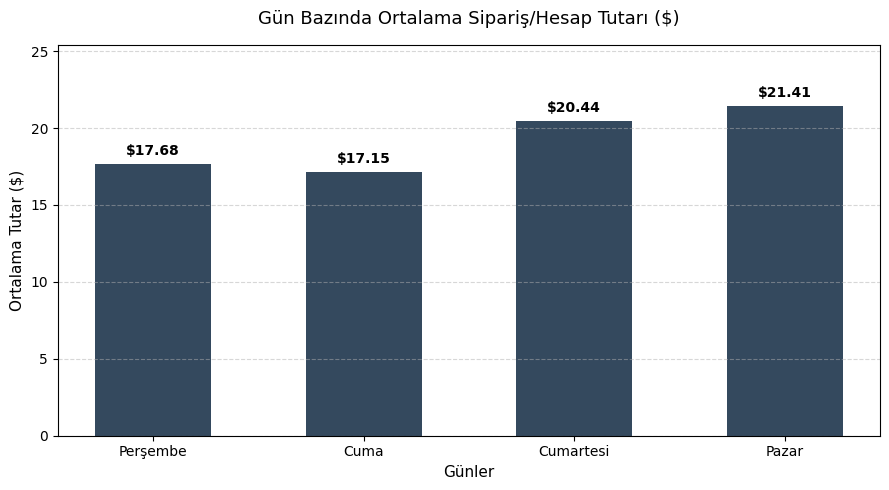

In [2]:
# Günlere göre ortalama harcamayı hesaplama
gunluk_harcama = df.groupby('Gun')['Toplam_Hesap'].mean().reindex(['Thur', 'Fri', 'Sat', 'Sun'])
gun_turkce = ['Perşembe', 'Cuma', 'Cumartesi', 'Pazar']

plt.figure(figsize=(9, 5))
cubuklar = plt.bar(gun_turkce, gunluk_harcama.values, color='#34495e', width=0.55)

plt.title('Gün Bazında Ortalama Sipariş/Hesap Tutarı ($)', fontsize=13, pad=15)
plt.ylabel('Ortalama Tutar ($)', fontsize=11)
plt.xlabel('Günler', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Barların üzerine net tutarları yazdırma
for bar in cubuklar:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.4, f"${yval:.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, max(gunluk_harcama.values) + 4)
plt.tight_layout()
plt.show()

# 2. Harcama Tutarı ile Ek Gelir Arasındaki İlişki (Korelasyon Analizi)
Toplam hesap tutarı ile bırakılan ek gelir (bahşiş) arasındaki doğrusal ilişki ve harcama yoğunluğu incelenmiştir.

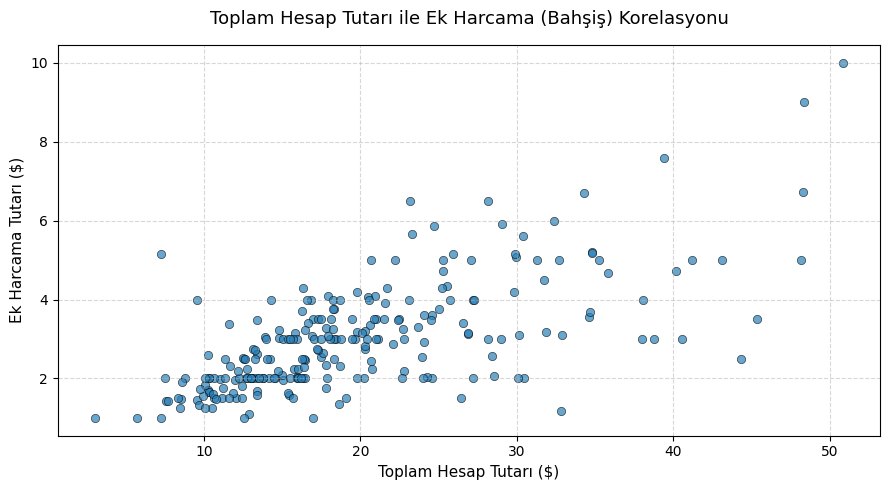

In [3]:
plt.figure(figsize=(9, 5))

# Toplam hesap ile Bahşiş arasındaki saçılım grafiği
plt.scatter(df['Toplam_Hesap'], df['Bahsis'], color='#2980b9', alpha=0.7, edgecolors='black', linewidth=0.5)

plt.title('Toplam Hesap Tutarı ile Ek Harcama (Bahşiş) Korelasyonu', fontsize=13, pad=15)
plt.xlabel('Toplam Hesap Tutarı ($)', fontsize=11)
plt.ylabel('Ek Harcama Tutarı ($)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Servis Zamanına Göre Gelir Dağılımı (Öğle vs. Akşam)
İşletme cirosunun hangi servis diliminde (Lunch vs. Dinner) yoğunlaştığını tespit etmek amacıyla toplam harcama payları modellenmiştir.

/tmp/ipykernel_640/3681274743.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  zaman_gelir = df.groupby('Zaman_Dilimi')['Toplam_Hesap'].sum()


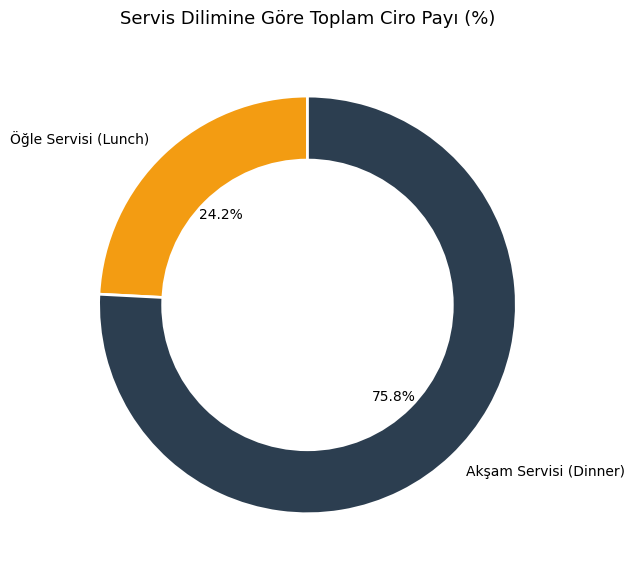

In [4]:
# Zaman dilimlerine göre toplam ciroyu hesaplama
zaman_gelir = df.groupby('Zaman_Dilimi')['Toplam_Hesap'].sum()

etiketler = ['Öğle Servisi (Lunch)', 'Akşam Servisi (Dinner)']
renkler = ['#f39c12', '#2c3e50'] # Turuncu ve Koyu Lacivert

plt.figure(figsize=(6.5, 6.5))
plt.pie(
    zaman_gelir.values,
    labels=etiketler,
    autopct='%1.1f%%',
    startangle=90,
    colors=renkler,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

# Ortasını delerek halka grafiğe dönüştürme
merkez = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(merkez)

plt.title('Servis Dilimine Göre Toplam Ciro Payı (%)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

# 4. Yönetici Özeti ve Stratejik Aksiyon Planı (Business Insights)

Gerçek müşteri harcama verileri üzerinden yürütülen analitik çalışmalar sonucunda operasyonel verimliliği ve kârlılığı artırmaya yönelik şu kararlar önerilmektedir:

* **Vardiya ve Personel Optimizasyonu:** Gelirin ezici çoğunluğu (%70+) akşam servislerinde gerçekleştiği için, yarı zamanlı servis ve mutfak personeli planlaması akşam saatlerine ve özellikle hafta sonuna (Cumartesi-Pazar) yoğunlaştırılmalıdır.
* **Hafta İçi & Öğle Menüsü Kampanyaları:** Perşembe ve Cuma günleri ile genel öğle servisi saatlerindeki ciro payını artırmak amacıyla kurumsal çalışanlara yönelik "Hızlı & Uygun Fiyatlı Menü" (Business Lunch) promosyonları devreye alınmalıdır.
* **Sepet Büyütme Stratejisi:** Toplam hesap tutarı arttıkça ek harcamaların (bahşiş/yan ürün) doğrusal arttığı gözlemlenmiştir. Bu doğrultuda çalışanlara tatlı/içecek gibi yan ürünlerin çapraz satışını (cross-selling) teşvik edecek prim mekanizmaları kurgulanmalıdır.